In [37]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from engression.loss_func import energy_loss, energy_loss_two_sample
import scipy.stats as stats
from graphlib import TopologicalSorter, _NodeInfo
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('PoliticalDemocracy.csv')
var_names = df.columns.values.tolist()
dataset = torch.tensor(df.to_numpy()).to(dtype = torch.float32)
batch_size = 25
dataloader = DataLoader(TensorDataset(dataset), batch_size = batch_size, shuffle = True)
print(var_names)

['y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'x1', 'x2', 'x3']


In [3]:
class rv_sem2(_NodeInfo):
    def __init__(self, formula: str):

        if "<-" in formula:
            lhs, rhs = formula.replace(" ", "").split("<-")
            super().__init__(lhs) # lhs is the variable name
            self.predecessors = rhs.split("+") # rhs is the parents of the node
            self.dist = None
            self.is_random = False
        elif "~" in formula:
            lhs, rhs = formula.replace(" ", "").split("~")
            super().__init__(lhs) # lhs is the variable name
            self.predecessors = []
            self.is_random = True
            self.dist = eval("stats."+rhs+"()") # rhs is the distribution (must be a class in scipy.stats)
        else:
            raise ValueError("Formula does not contain <- or ~.")

        self.npredecessors = len(self.predecessors) # NOTE: this will be changed when obtaining topological order
        self.formula = formula

    def __repr__(self):
        return self.formula

In [4]:
class sem2(TopologicalSorter, nn.Module):
    def __init__(self, model_formula = None):

        nn.Module.__init__(self)
        TopologicalSorter.__init__(self, graph = None)

        formula_list = model_formula.replace(" ", "").split(";")

        # Initialize node info by formula
        var = [rv_sem2(formula) for formula in formula_list]
        self._node2info = {v.node:v for v in var}                
        
        for node, v in self._node2info.items():                
            for p in v.predecessors:
                self._node2info[p].successors.append(node)

        self.layer = nn.ModuleDict()
        for node, v in self._node2info.items():
            if v.is_random is True:
                self.layer[node] = None
            else:
                self.layer[node] = nn.Linear(len(v.predecessors), 1)

        self._topological_order = list(super(sem2, self).static_order())
        self._node2index = {node: index for index, node in enumerate(self._topological_order)}
    
    def _get_nodeinfo(self, node: str):
        """Override original private method, raise an error if node does not exist
        """
        return self._node2info[node]

    def add(self, node, *predecessors):
        """Override original methods, don't do anything
        """
        return None

    def static_order(self):
        """Override static_order to return cached topological order"""
        return iter(self._topological_order)

    def forward(self, batch_size = 1):
        n_nodes = len(self._node2info)
        x = torch.zeros(batch_size, n_nodes)
        for node in self._topological_order:
            v = self._node2info[node]
            index = self._node2index[node]
            if v.is_random is True:
                 x[:, index] = torch.tensor(v.dist.rvs(batch_size))
            else:
                pred_indices = [self._node2index[p] for p in v.predecessors]
                x[:, index] = self.layer[node](x[:, pred_indices]).squeeze(-1)
        return x

In [5]:
model_formula = "X <- A + B + C; B <- A + C; A ~ uniform; C ~ norm"
model = sem2(model_formula)
var = model._node2info
[var, 
 var["A"].dist.rvs(10), var["C"].dist.rvs(10), 
 var["A"].successors, var["B"].predecessors, model._topological_order]

[{'X': X<-A+B+C, 'B': B<-A+C, 'A': A~uniform, 'C': C~norm},
 array([0.08767618, 0.91832697, 0.94635848, 0.95857007, 0.56019363,
        0.53417788, 0.47591196, 0.93213024, 0.13414278, 0.03878628]),
 array([ 0.52825196, -0.02653201, -0.96517329,  1.54042515, -0.35716726,
        -0.2820985 , -0.28114596, -0.07464935, -1.7611612 , -0.34855243]),
 ['X', 'B'],
 ['A', 'C'],
 ['A', 'C', 'B', 'X']]

In [6]:
model(8)

tensor([[ 0.5368,  1.4603, -0.8225,  0.2825],
        [ 0.0046,  0.4046, -0.5980,  0.2202],
        [ 0.9223, -0.0109, -0.3906,  0.5639],
        [ 0.8129,  0.5856, -0.5608,  0.4651],
        [ 0.7328,  0.5272, -0.5537,  0.4452],
        [ 0.2330,  0.9868, -0.7286,  0.2333],
        [ 0.5792, -0.7459, -0.2314,  0.5295],
        [ 0.1640, -1.3766, -0.1075,  0.4605]], grad_fn=<CopySlices>)

In [7]:
# Linear factor model
model_formula = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3; ind60 ~ norm; ex1 ~ norm; ex2 ~ norm; ex3 ~ norm"
model = sem2(model_formula)
observed_var = ["x1", "x2", "x3"]
x = dataset[:, [var_names.index(var) for var in observed_var]]
observed_index = [list(model.static_order()).index(var) for var in observed_var]

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for i in range(1000):
    optimizer.zero_grad()
    sample1 = model(x.size(0))[:, observed_index]
    sample2 = model(x.size(0))[:, observed_index]
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 7.4191, s1: 8.1518, s2: 1.4654
Iter 100 | loss: 4.6738, s1: 6.7960, s2: 4.2444
Iter 200 | loss: 3.4703, s1: 6.2965, s2: 5.6524
Iter 300 | loss: 2.9624, s1: 5.8193, s2: 5.7138
Iter 400 | loss: 2.7197, s1: 4.9561, s2: 4.4727
Iter 500 | loss: 1.7697, s1: 4.2894, s2: 5.0395
Iter 600 | loss: 1.3094, s1: 3.4035, s2: 4.1881
Iter 700 | loss: 1.2844, s1: 3.1741, s2: 3.7795
Iter 800 | loss: 1.4157, s1: 2.8540, s2: 2.8766
Iter 900 | loss: 1.3155, s1: 2.6324, s2: 2.6339
Iter 1000 | loss: 1.5262, s1: 2.7744, s2: 2.4964


In [9]:
beta = [model.layer[node].weight[0][0].squeeze().detach().numpy().tolist() for node in observed_var]
[beta[i] / beta[0] for i in range(3)]

[1.0, 2.1129665515207683, 1.9605148078024355]

In [10]:
# # Linear factor model (same as lavaan package example)
# formula_epsx = "ex1 ~ norm; ex2 ~ norm; ex3 ~ norm;" 
# formula_epsy = "ey1 ~ norm; ey2 ~ norm; ey3 ~ norm; ey4 ~ norm; ey5 ~ norm; ey6 ~ norm; ey7 ~ norm; ey8 ~ norm;"
# formula_epsdem = "edem60 ~ norm; edem65 ~ norm;"
# formula_epscov = "e15 ~ norm; e24 ~ norm; e26 ~ norm; e37 ~ norm; e48 ~ norm; e68 ~ norm;"
# formula_end = "ind60 ~ norm; dem60 <- ind60 + edem60; dem65 <- ind60 + dem60 + edem65;"
# formula_x = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3;"
# formula_y1 = "y1 <- dem60 + ey1 + e15; y2 <- dem60 + ey2 + e24 + e26; y3 <- dem60 + ey3 + e37; y4 <- dem60 + ey4 + e24 + e48;"
# formula_y2 = "y5 <- dem65 + ey5 + e15; y6 <- dem65 + ey6 + e26; y7 <- dem65 + ey7 + e37; y8 <- dem65 + ey8 + e48 + e68"
# formula = formula_epsx + formula_epsy + formula_epsdem + formula_epscov + formula_end + formula_x + formula_y1 + formula_y2

In [44]:
# Linear factor model (without residual correlations)
formula_epsx = "ex1 ~ norm; ex2 ~ norm; ex3 ~ norm;" 
formula_epsy = "ey1 ~ norm; ey2 ~ norm; ey3 ~ norm; ey4 ~ norm; ey5 ~ norm; ey6 ~ norm; ey7 ~ norm; ey8 ~ norm;"
formula_epsdem = "edem60 ~ norm; edem65 ~ norm;"
formula_end = "ind60 ~ norm; dem60 <- ind60 + edem60; dem65 <- ind60 + dem60 + edem65;"
formula_x = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3;"
formula_y1 = "y1 <- dem60 + ey1; y2 <- dem60 + ey2; y3 <- dem60 + ey3; y4 <- dem60 + ey4;"
formula_y2 = "y5 <- dem65 + ey5; y6 <- dem65 + ey6; y7 <- dem65 + ey7; y8 <- dem65 + ey8"
formula = formula_epsx + formula_epsy + formula_epsdem + formula_end + formula_x + formula_y1 + formula_y2
lavaan_coefs = [1.483, 0.572, 0.837]

In [12]:
observed_var = var_names
x = dataset[:, [var_names.index(var) for var in observed_var]]
model = sem2(formula)
observed_index = [list(model.static_order()).index(var) for var in observed_var]

In [57]:
# vanilla energy loss minimization
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
niter = 10000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
#    sample1 = model(x.size(0))[:, observed_index]
#    sample2 = model(x.size(0))[:, observed_index]
#    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    sample = model(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0]
    dem60_scale = model.layer["y1"].weight[0][0]
    dem65_scale = model.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 17.0604, s1: 18.1589, s2: 2.1970
[-0.29076311  0.34496012 -0.37011129]
Iter 1000 | loss: 6.2447, s1: 12.5812, s2: 12.6730
[3.23081303 1.14551699 0.7942571 ]
Iter 2000 | loss: 6.1680, s1: 12.4983, s2: 12.6606
[2.37103629 0.85037142 0.75947118]
Iter 3000 | loss: 6.1541, s1: 12.5193, s2: 12.7304
[1.77720654 0.70068961 0.78478158]
Iter 4000 | loss: 6.1948, s1: 12.4916, s2: 12.5936
[1.69224656 0.78760558 0.80992568]
Iter 5000 | loss: 6.1192, s1: 12.5432, s2: 12.8480
[1.50735152 0.5482105  0.82210076]
Iter 6000 | loss: 6.0963, s1: 12.4012, s2: 12.6098
[1.53888977 0.52866435 0.81570125]
Iter 7000 | loss: 6.2577, s1: 12.6135, s2: 12.7116
[1.91671705 0.57023525 0.80133462]
Iter 8000 | loss: 6.1770, s1: 12.5483, s2: 12.7427
[1.99062371 0.58723295 0.79491287]
Iter 9000 | loss: 6.3133, s1: 12.7249, s2: 12.8232
[1.35791337 0.4389751  0.81385785]
Iter 10000 | loss: 6.1969, s1: 12.5906, s2: 12.7873
[1.78660834 0.60148364 0.79736018]


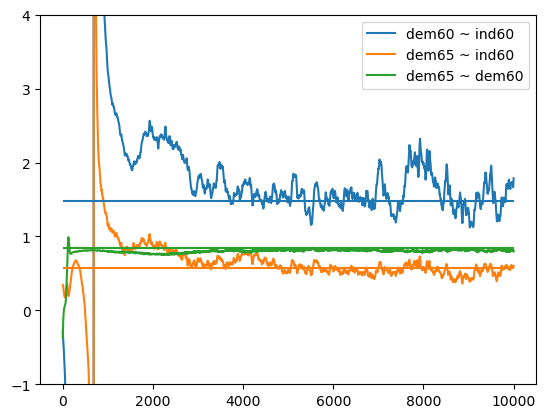

In [60]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()

In [63]:
# change loss function to OLS (between sample and model covariance matrices)
sample_cov = torch.cov(torch.t(x))
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-2)
model.train()
niter = 5000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    model_sample = model(x.size(0) * 10)[:, observed_index]
    model_cov = torch.cov(torch.t(model_sample))
    loss = torch.norm(sample_cov - model_cov)
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0]
    dem60_scale = model.layer["y1"].weight[0][0]
    dem65_scale = model.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 59.1875, s1: 12.5906, s2: 12.7873
[-0.0593204  -0.35176611 -0.3237288 ]
Iter 1000 | loss: 6.2810, s1: 12.5906, s2: 12.7873
[2.88341761 1.40040517 0.7260955 ]
Iter 2000 | loss: 5.4135, s1: 12.5906, s2: 12.7873
[1.55434    0.60814267 0.8354587 ]
Iter 3000 | loss: 5.4904, s1: 12.5906, s2: 12.7873
[1.30399251 0.42881012 0.8275941 ]
Iter 4000 | loss: 5.4896, s1: 12.5906, s2: 12.7873
[1.39627719 0.47627154 0.84382671]
Iter 5000 | loss: 5.3699, s1: 12.5906, s2: 12.7873
[1.32169247 0.42385769 0.82982683]


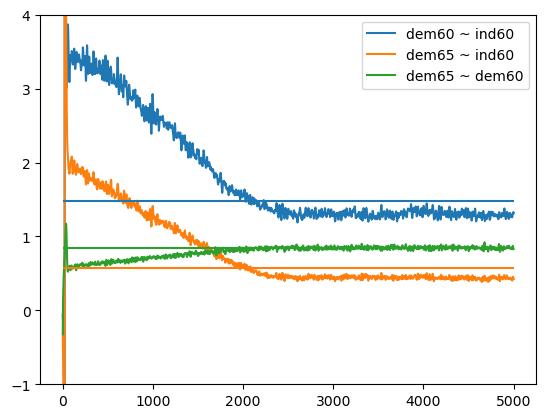

In [65]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()

In [66]:
# change loss function to negative log likelihood
sample_cov = torch.cov(torch.t(x))
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-2)
model.train()
niter = 5000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    model_sample = model(x.size(0) * 10)[:, observed_index]
    model_cov = torch.cov(torch.t(model_sample))
    loss = torch.log(torch.det(model_cov)) + torch.trace(sample_cov @ torch.inverse(model_cov))
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0]
    dem60_scale = model.layer["y1"].weight[0][0]
    dem65_scale = model.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 658.9762, s1: 12.5906, s2: 12.7873
[-0.11599269 -0.46410155  0.31505466]
Iter 1000 | loss: 22.1686, s1: 12.5906, s2: 12.7873
[1.46447074 0.43907002 0.73741293]
Iter 2000 | loss: 21.6151, s1: 12.5906, s2: 12.7873
[1.48307812 0.44899899 0.82565945]
Iter 3000 | loss: 21.7870, s1: 12.5906, s2: 12.7873
[1.42017984 0.41042203 0.84415799]
Iter 4000 | loss: 21.8384, s1: 12.5906, s2: 12.7873
[1.47569299 0.45855075 0.88722944]
Iter 5000 | loss: 21.6479, s1: 12.5906, s2: 12.7873
[1.46879697 0.47273794 0.88981652]


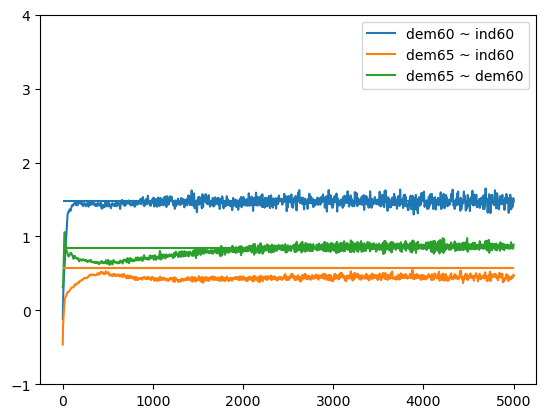

In [67]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()

In [68]:
x = dataset[:, [var_names.index(var) for var in observed_var]]
sd = torch.std(x, dim = 0)
print(sd)
x_normalized = torch.zeros_like(x)
for i in range(x.size(1)):
    x_normalized[:,i] = x[:,i] / sd[i]

tensor([2.6227, 3.9471, 3.2809, 3.3495, 2.6126, 3.3727, 3.2862, 3.2456, 0.7329,
        1.5107, 1.4057])


In [69]:
# Try normalizing before energy loss minimization
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
niter = 10000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 8.8358, s1: 10.0729, s2: 2.4742
[ 1.54826033 -1.01209676 -0.02080462]
Iter 1000 | loss: 2.2311, s1: 4.4962, s2: 4.5302
[1.75843537 0.9324345  0.70388383]
Iter 2000 | loss: 2.1773, s1: 4.4249, s2: 4.4952
[1.79858851 0.71275073 0.81036216]
Iter 3000 | loss: 2.2134, s1: 4.4616, s2: 4.4963
[1.54978263 0.64631349 0.82359397]
Iter 4000 | loss: 2.1769, s1: 4.4214, s2: 4.4890
[1.71040583 0.66004294 0.84383178]
Iter 5000 | loss: 2.2051, s1: 4.4359, s2: 4.4614
[1.6702137  0.61554438 0.83604407]
Iter 6000 | loss: 2.2151, s1: 4.4896, s2: 4.5491
[1.5999372  0.61563146 0.83094966]
Iter 7000 | loss: 2.2079, s1: 4.4541, s2: 4.4926
[1.58680654 0.70077091 0.83973038]
Iter 8000 | loss: 2.2144, s1: 4.4419, s2: 4.4551
[1.61094642 0.68389338 0.81471652]
Iter 9000 | loss: 2.1816, s1: 4.4249, s2: 4.4866
[1.8561852  0.71220016 0.81870675]
Iter 10000 | loss: 2.2084, s1: 4.4633, s2: 4.5099
[1.78753352 0.66678333 0.80883765]


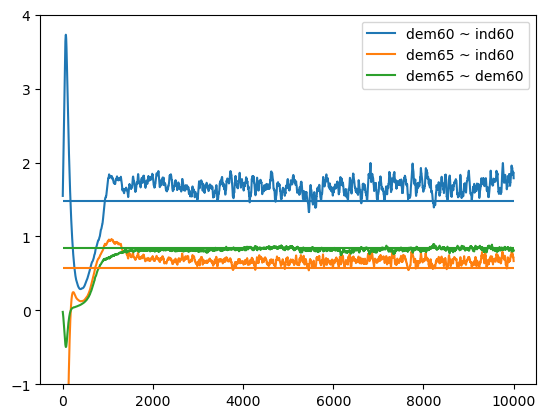

In [71]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()

In [74]:
# Try smaller sample size to approximate energy loss
model = sem2(formula)
optimizer = torch.optim.Adam(model.parameters(), lr=2e-3)
model.train()
niter = 20000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model(x.size(0) * 2)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 8.8729, s1: 10.0172, s2: 2.2885
[ -0.08423167  -3.26953077 -14.17628384]
Iter 1000 | loss: 4.4599, s1: 8.8012, s2: 8.6825
[10.07060146 -7.07182217  0.15146172]
Iter 2000 | loss: 3.0482, s1: 6.5373, s2: 6.9783
[ 3.1473732  -1.91952109  0.29688737]
Iter 3000 | loss: 2.6628, s1: 5.3771, s2: 5.4285
[ 2.68980551 -0.84784865  0.41892505]
Iter 4000 | loss: 2.1330, s1: 4.6121, s2: 4.9583
[3.49953365 0.34129018 0.66578585]
Iter 5000 | loss: 2.2790, s1: 4.6586, s2: 4.7593
[2.85016537 0.89586413 0.7351734 ]
Iter 6000 | loss: 2.3347, s1: 4.5711, s2: 4.4727
[2.32854152 0.83852589 0.74108118]
Iter 7000 | loss: 2.2048, s1: 4.4140, s2: 4.4185
[1.93730593 0.74180341 0.76918352]
Iter 8000 | loss: 2.4875, s1: 4.8330, s2: 4.6909
[1.76566756 0.68477333 0.77705008]
Iter 9000 | loss: 2.0649, s1: 4.3333, s2: 4.5368
[1.8534956  0.76933348 0.76638716]
Iter 10000 | loss: 2.2130, s1: 4.4332, s2: 4.4404
[1.72562134 0.67183095 0.76903504]
Iter 11000 | loss: 2.1469, s1: 4.3803, s2: 4.4668
[1.76917827 

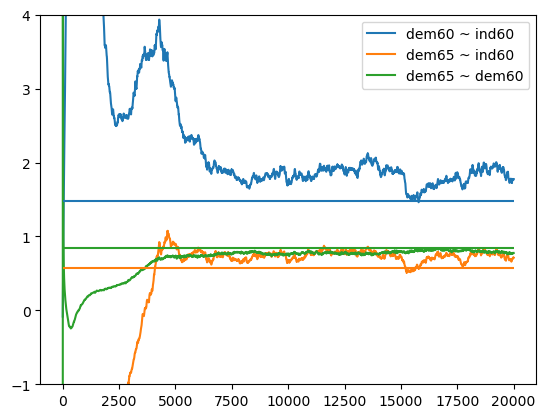

In [75]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-1, 4)
plt.legend()